In [1]:
#yfinance is a popular Python library used for downloading historical market data from Yahoo Finance.
#It simplifies the process of accessing financial data for various securities, including stocks, commodities, cryptocurrencies, and mor
#pip install yfinance

In [2]:
import seaborn as sns
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
#from sklearn import metrics
#from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
#The code fetches historical price data for Bitcoin, Ethereum, Tether, and Binance Coin for the past 5 years and keeps only the Close and Volume columns for each of these cryptocurrencies.
#This cleaned data can then be used for further analysis or machine learning tasks, such as predicting future prices.


btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='5y')
prices1.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'],inplace = True, errors='ignore')

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='5y')
prices2.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'],inplace = True,errors='ignore')

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='5y')
prices3.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'],inplace = True,errors='ignore')

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='5y')
prices4.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'],inplace = True,errors='ignore')

In [4]:
#The parameters lsuffix and rsuffix in the join method are used to add suffixes to overlapping column names when joining two DataFrames
# This is necessary to avoid column name conflicts when the two DataFrames have columns with the same name.

p1 = prices1.join(prices2, lsuffix = ' (BTC)', rsuffix = ' (ETH)')
p2 = prices3.join(prices4, lsuffix = ' (USDT)', rsuffix = ' (BNB)')
data = p1.join(p2, lsuffix = '_', rsuffix = '_')

In [5]:
data.head()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2021-10-10 00:00:00+00:00,54771.578125,39527792364,3425.852783,16171746693,1.001018,69927661418,405.069305,1437068558
2021-10-11 00:00:00+00:00,57484.789062,42637331698,3545.354004,18579189588,1.000696,75741431317,413.456207,1473121389
2021-10-12 00:00:00+00:00,56041.058594,41083758949,3492.573242,18109578443,1.000096,73275476508,443.867523,3142304145
2021-10-13 00:00:00+00:00,57401.097656,41684252783,3606.201660,16211275589,1.000097,78117249743,470.749695,5149146903
2021-10-14 00:00:00+00:00,57321.523438,36615791366,3786.014160,19443499909,1.000034,68955958208,472.022400,2486819344


In [6]:
data.tail()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2026-10-06 00:00:00+00:00,85557.562500,25245965925,2697.516357,10986122667,0.999845,60953147088,779.615967,1273219160
2026-10-07 00:00:00+00:00,83275.929688,38737709051,2573.527344,20082324906,0.999445,88736239765,772.301270,1545007708
2026-10-08 00:00:00+00:00,81676.335938,46221063868,2471.912598,20081062061,0.999441,98439415752,735.130920,1908359378
2026-10-09 00:00:00+00:00,82546.320312,24521046869,2485.538574,9046002553,0.999112,58864228656,742.094421,1316740996
2026-10-10 00:00:00+00:00,82704.156250,21207033856,2492.100098,7259038208,0.999030,52363698176,749.200012,1224179456


In [7]:
data.shape

(1827, 8)

In [8]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-10 00:00:00+00:00 to 2026-10-10 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1827 non-null   float64
 1   Volume (BTC)   1827 non-null   int64  
 2   Close (ETH)    1827 non-null   float64
 3   Volume (ETH)   1827 non-null   int64  
 4   Close (USDT)   1827 non-null   float64
 5   Volume (USDT)  1827 non-null   int64  
 6   Close (BNB)    1827 non-null   float64
 7   Volume (BNB)   1827 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.5 KB


In [9]:
data.isna().sum()

Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [10]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03
mean,58862.297981,3.467121e+10,2511.336763,1.759518e+10,0.999976,6.770978e+10,509.834767,1.630831e+09
std,29836.705113,2.057476e+10,881.009850,1.183644e+10,0.000659,4.222764e+10,219.229270,1.091223e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29412.204102,2.041515e+10,1810.192871,9.450992e+09,0.999676,3.933162e+10,304.748932,9.030619e+08
50%,60867.414062,3.018029e+10,2372.201904,1.502804e+10,1.000062,5.806068e+10,553.972290,1.520731e+09
75%,82410.117188,4.262689e+10,3132.209229,2.171727e+10,1.000284,8.340095e+10,639.358093,2.017240e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


#Exploratory Data Analysis

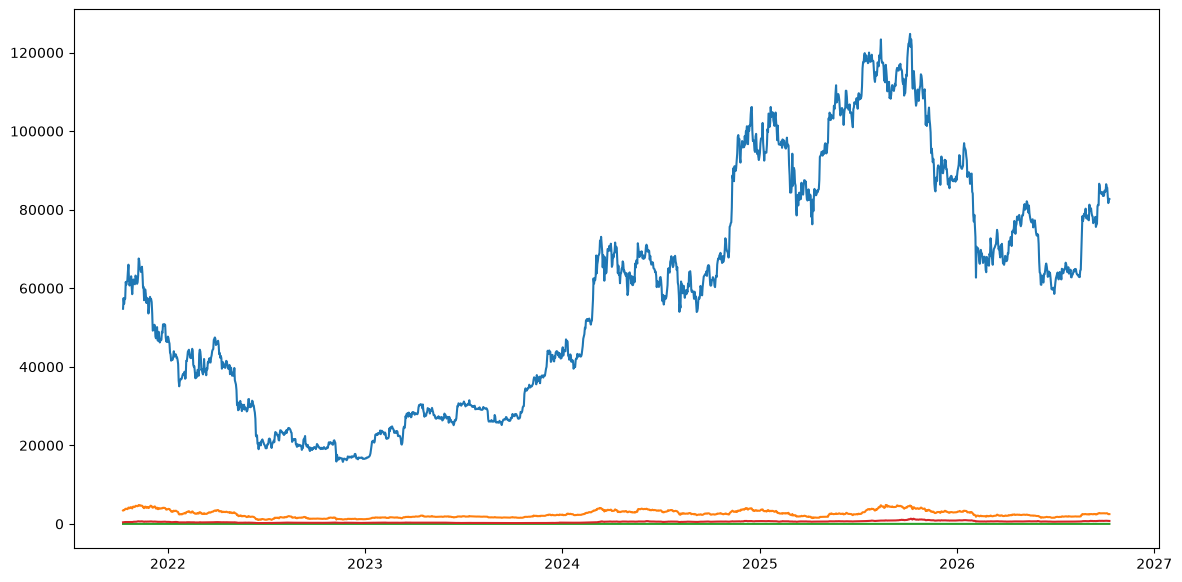

In [11]:
# Visualize the Closing Prices
# create a line plot to visualize the closing prices of all four cryptocurrencies over time:
plt.figure(figsize=(14,7))
plt.plot(data.index, data['Close (BTC)'], label = 'Bitcoin (BTC)')
plt.plot(data.index, data['Close (ETH)'],label = 'Ethereum(ETH)')
plt.plot(data.index, data['Close (USDT)'],label = 'Tether(USDT)')
plt.plot(data.index, data['Close (BNB)'],label = 'Binance Coin(BNB)')

<Axes: xlabel='Date'>

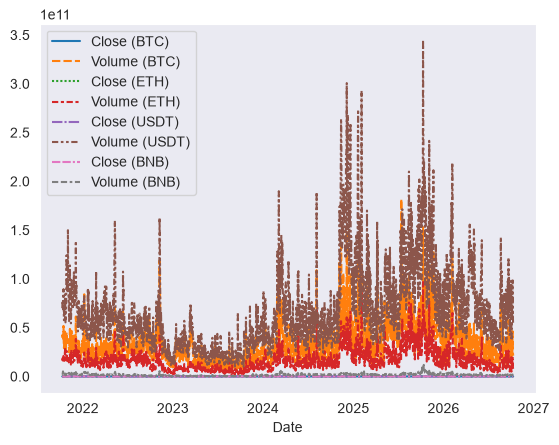

In [12]:
plt.Figure(figsize= (25,5))
sns.set_style('dark')
sns.lineplot(data = data)

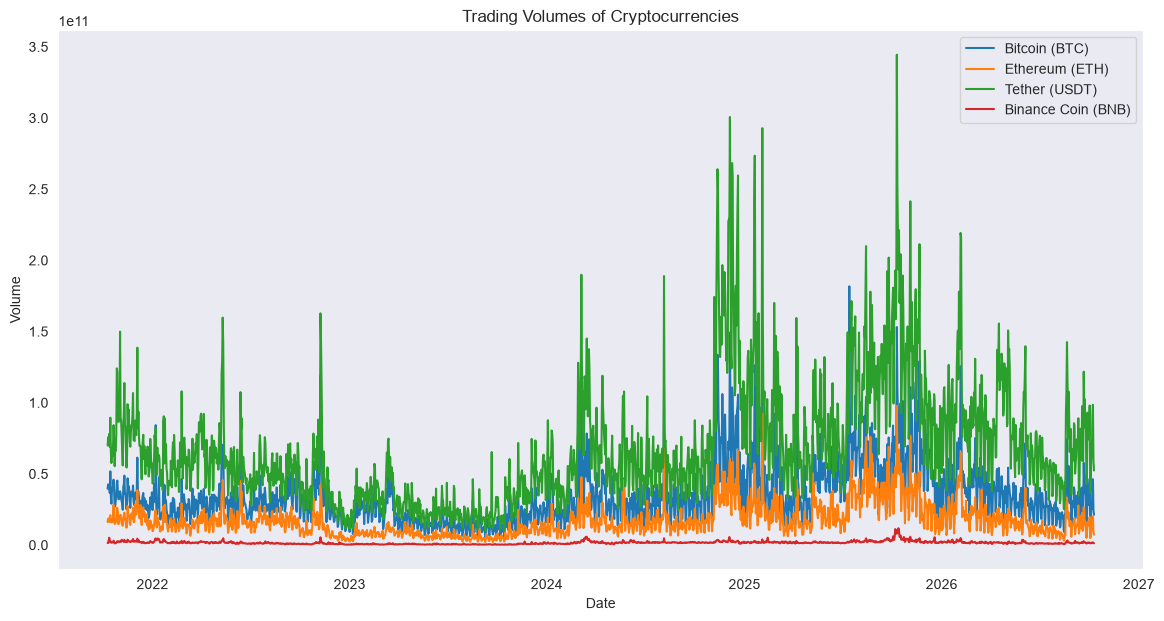

In [13]:
# Visualize the Trading Volumes
#Let's visualize the trading volumes of all four cryptocurrencies:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()

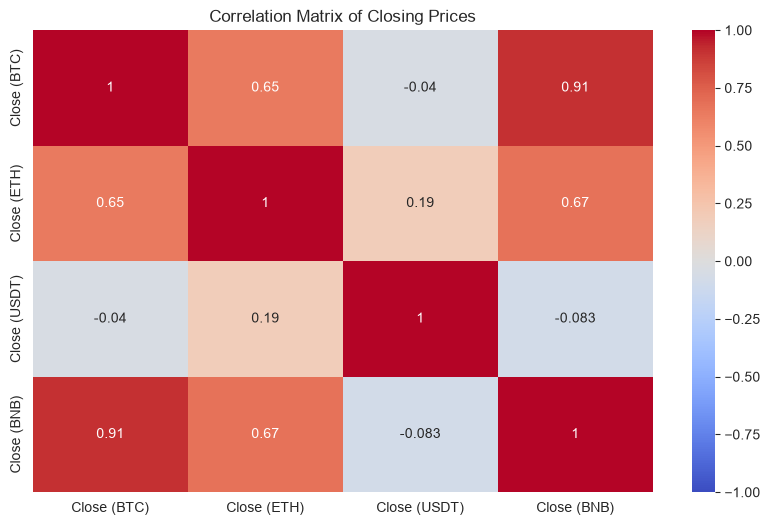

In [14]:
 #Correlation Analysis
#We'll analyze the correlation between the closing prices of the cryptocurrencies:
# Calculate the correlation matrix
corr_matrix = data[['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Closing Prices')
plt.show()


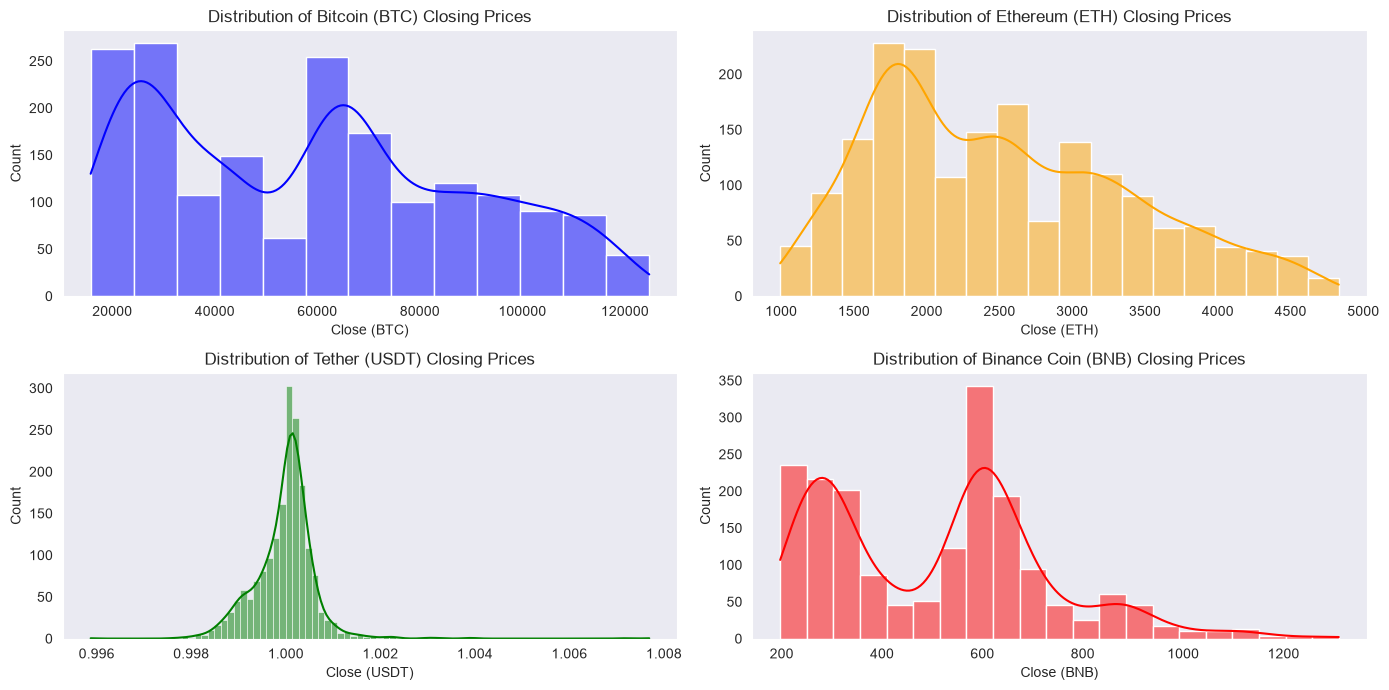

In [15]:
# Distribution of Closing Prices
#Let's plot the distribution of closing prices for each cryptocurrency:
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()


array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

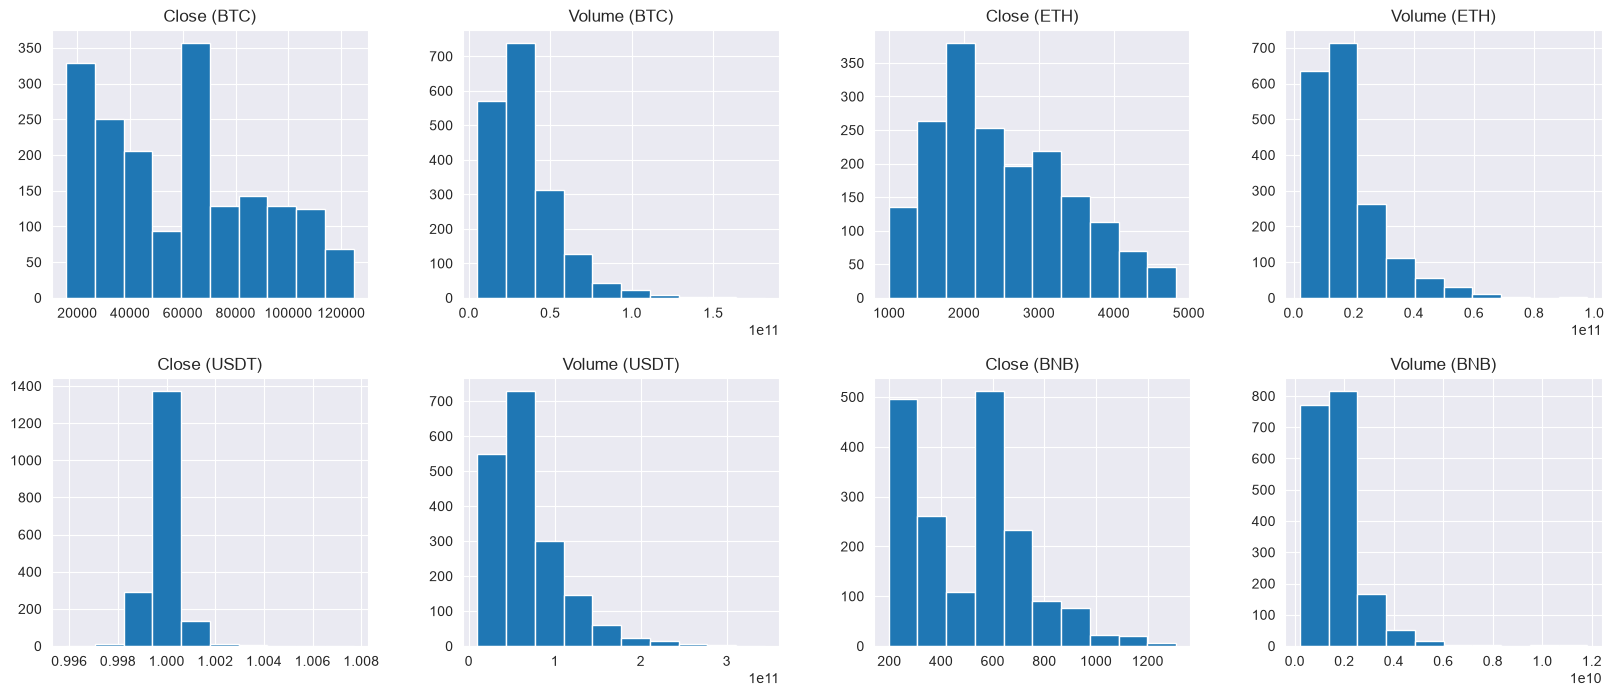

In [16]:
data.hist(figsize=(20,8),layout = (2,4))

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

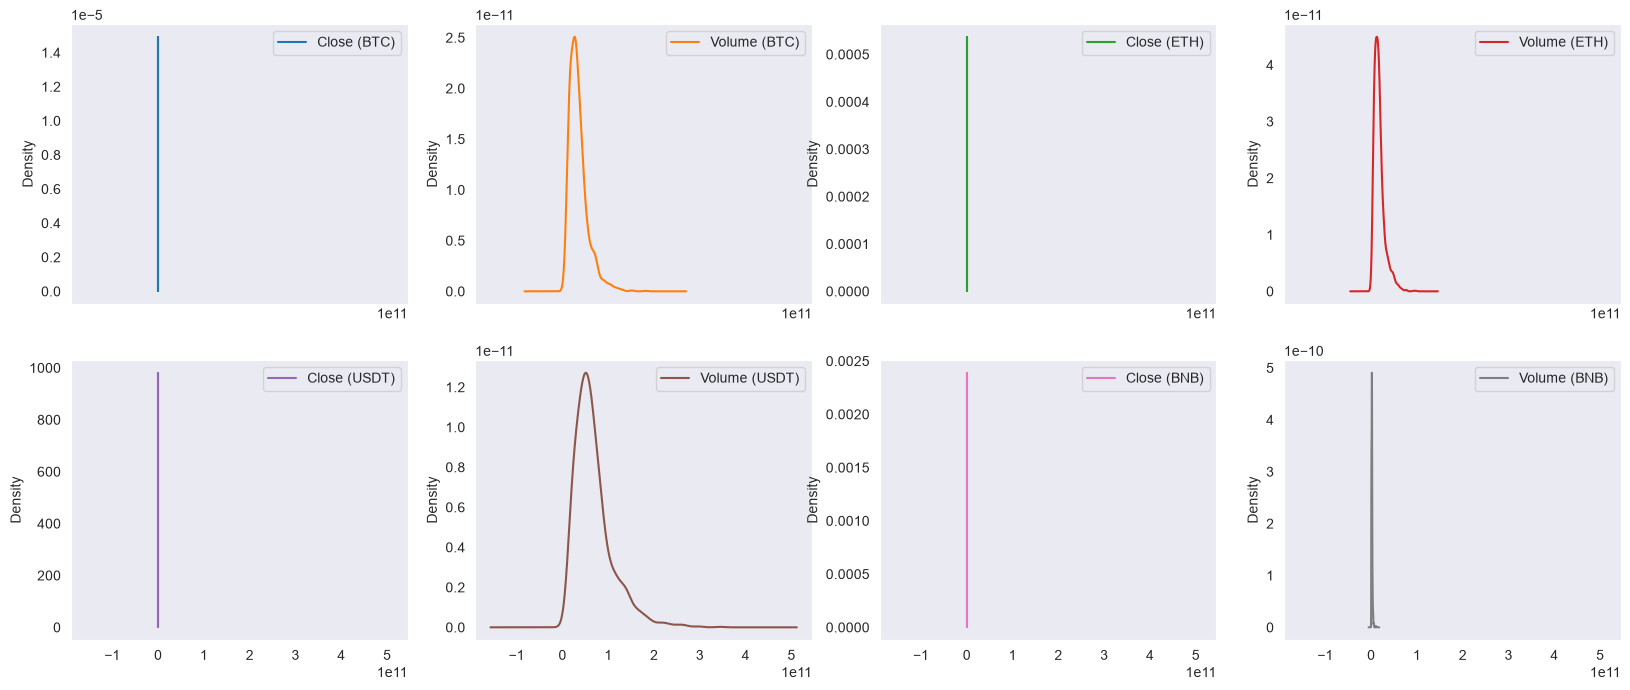

In [17]:
data.plot(kind="kde",subplots= True,layout=(2,4),figsize=(20,8))

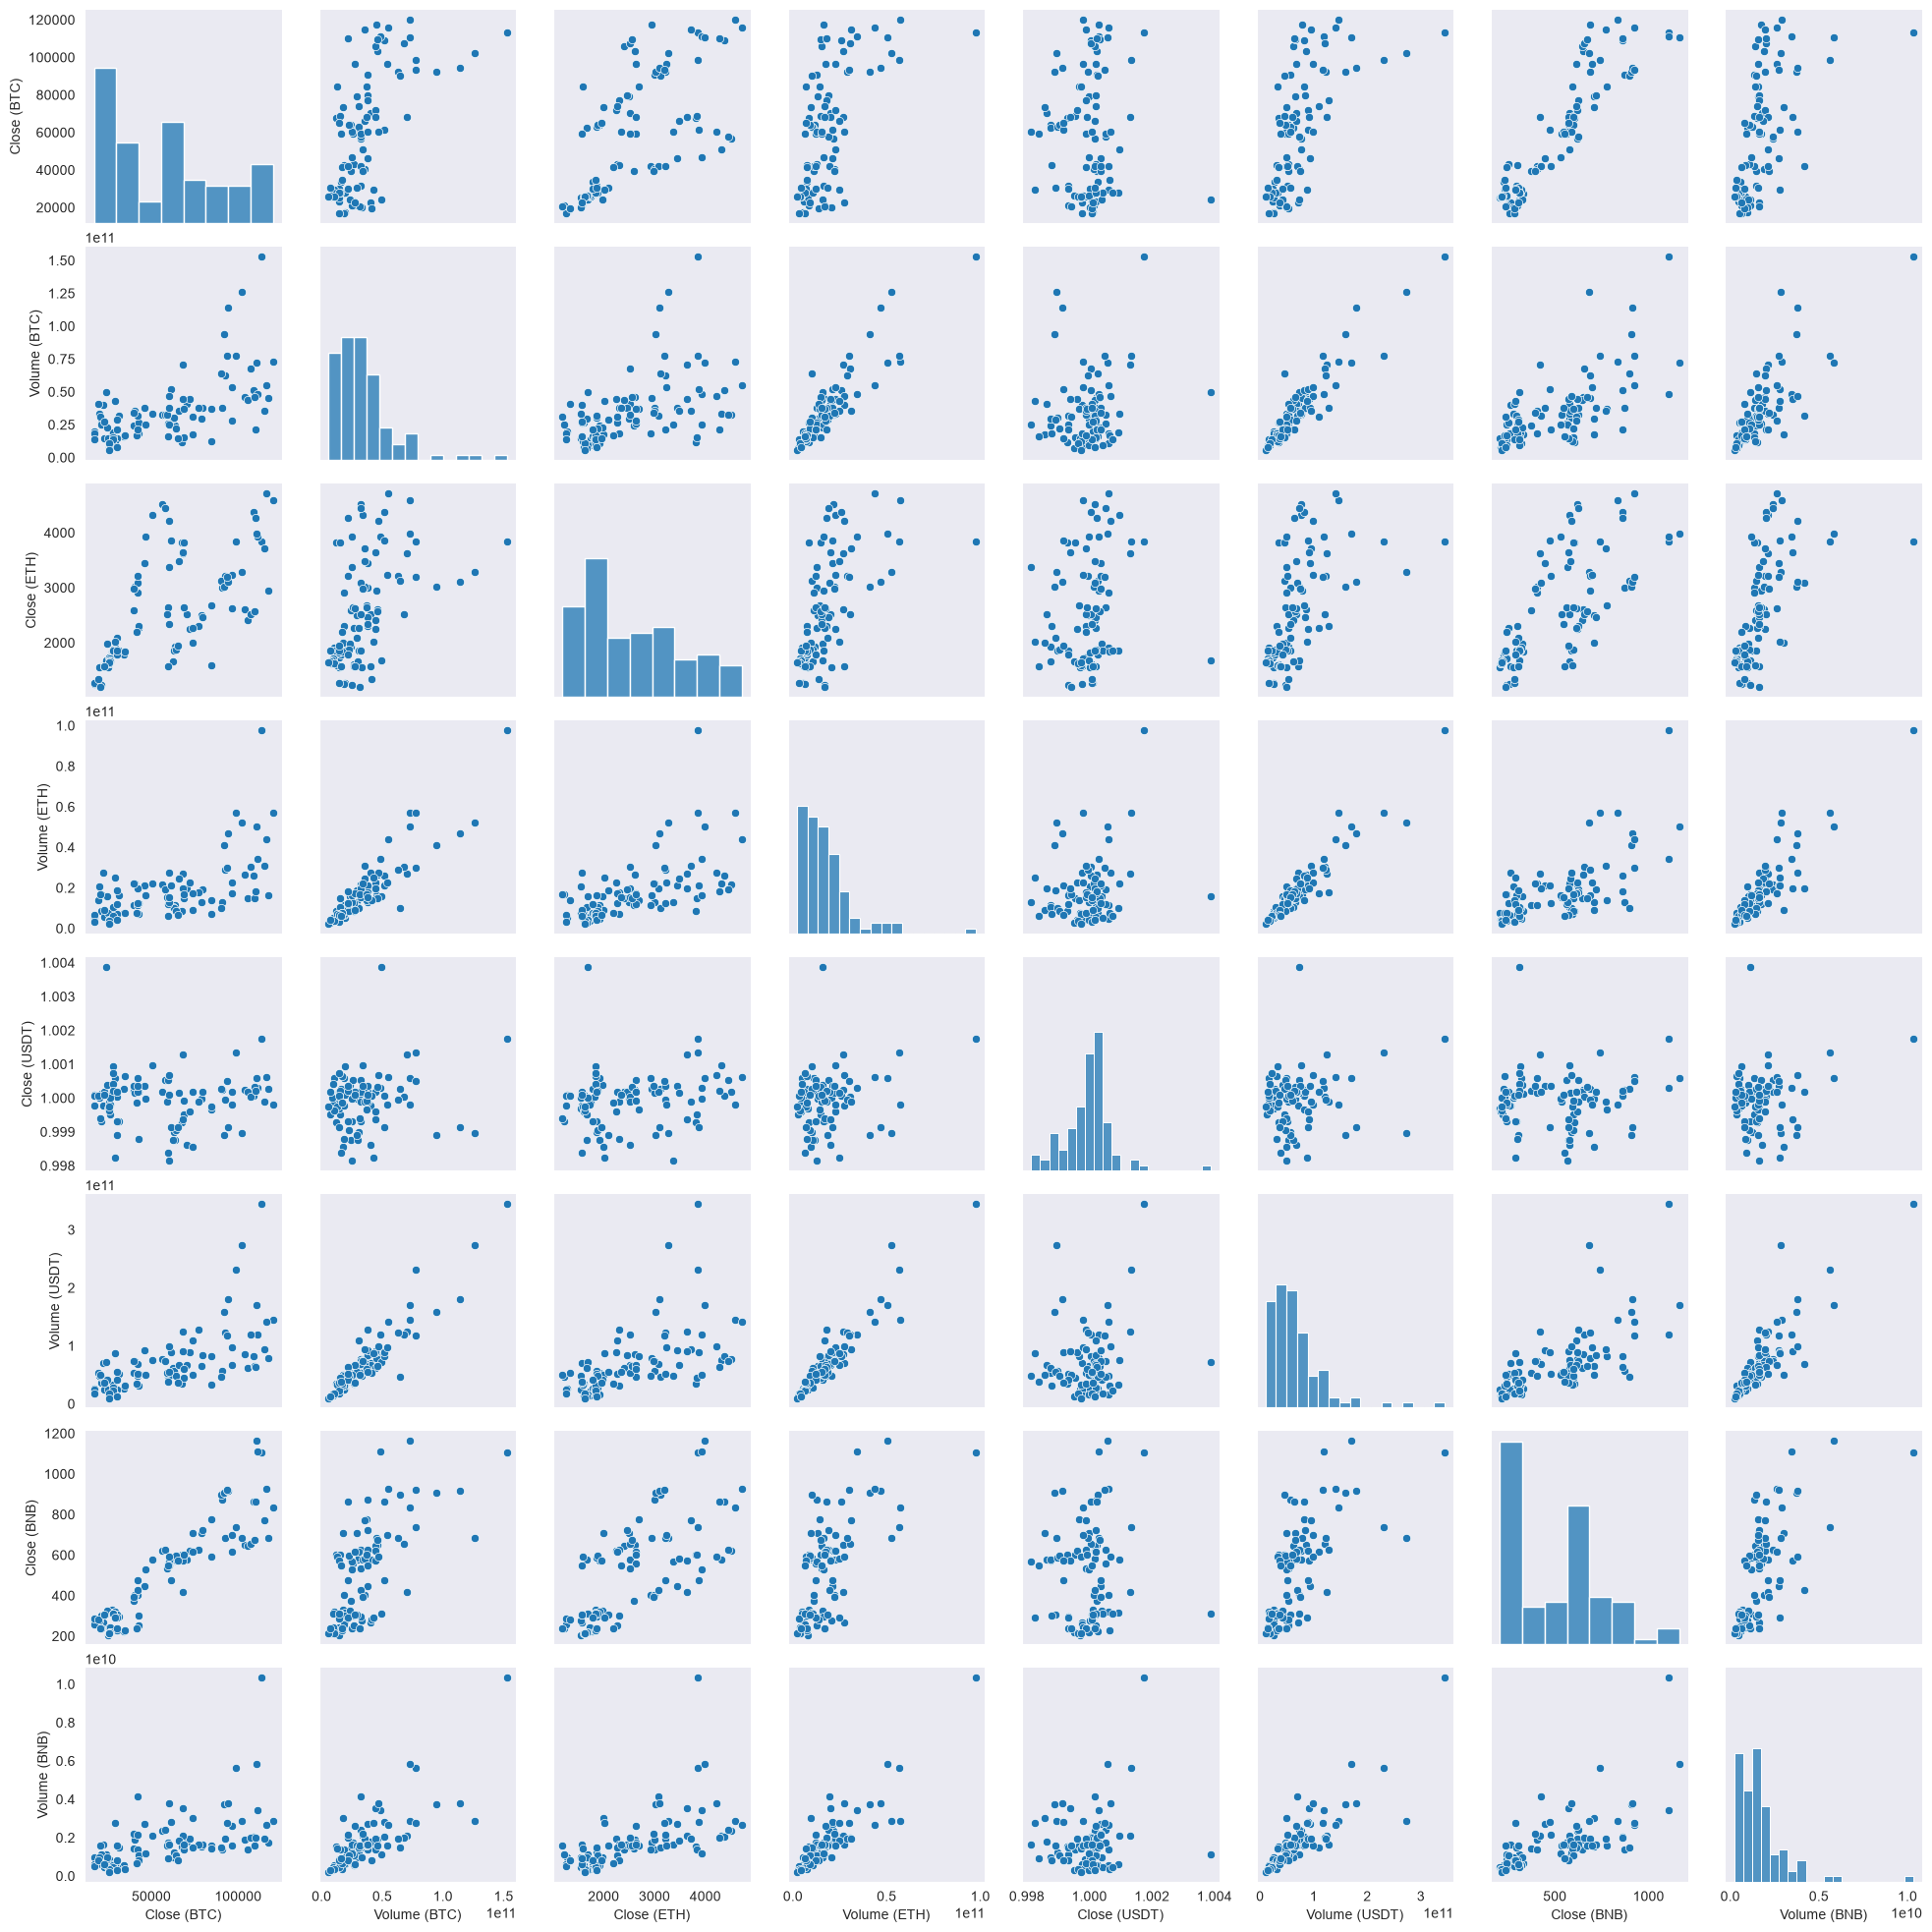

In [18]:
sns.pairplot(data.sample(n=100))

In [19]:
X = data.drop(columns= ['Close (BTC)'])
Y = data.loc[:,'Close (BTC)']

In [20]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-10-10 00:00:00+00:00,39527792364,3425.852783,16171746693,1.001018,69927661418,405.069305,1437068558
2021-10-11 00:00:00+00:00,42637331698,3545.354004,18579189588,1.000696,75741431317,413.456207,1473121389
2021-10-12 00:00:00+00:00,41083758949,3492.573242,18109578443,1.000096,73275476508,443.867523,3142304145
2021-10-13 00:00:00+00:00,41684252783,3606.201660,16211275589,1.000097,78117249743,470.749695,5149146903
2021-10-14 00:00:00+00:00,36615791366,3786.014160,19443499909,1.000034,68955958208,472.022400,2486819344


In [21]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-10-06 00:00:00+00:00,25245965925,2697.516357,10986122667,0.999845,60953147088,779.615967,1273219160
2026-10-07 00:00:00+00:00,38737709051,2573.527344,20082324906,0.999445,88736239765,772.301270,1545007708
2026-10-08 00:00:00+00:00,46221063868,2471.912598,20081062061,0.999441,98439415752,735.130920,1908359378
2026-10-09 00:00:00+00:00,24521046869,2485.538574,9046002553,0.999112,58864228656,742.094421,1316740996
2026-10-10 00:00:00+00:00,21207033856,2492.100098,7259038208,0.999030,52363698176,749.200012,1224179456


In [22]:
Y.head()

Date
2021-10-10 00:00:00+00:00    54771.578125
2021-10-11 00:00:00+00:00    57484.789062
2021-10-12 00:00:00+00:00    56041.058594
2021-10-13 00:00:00+00:00    57401.097656
2021-10-14 00:00:00+00:00    57321.523438
Name: Close (BTC), dtype: float64

In [23]:
# split the data info training and testing sets
X_train, X_test , Y_train, Y_test = train_test_split(X,Y, test_size=0.2,random_state=0)

In [24]:
# Print the shapes of the resulting datasets
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1461, 7)
X_test shape: (366, 7)
y_train shape: (1461,)
y_test shape: (366,)


In [25]:
#SelectKBest
#SelectKBest is a feature selection method provided by scikit-learn (sklearn) that selects the top k features based on a specified scoring function.
#This function evaluates each feature independently and selects those that have the strongest relationship with the target variable.

#Parameters
#k: Specifies the number of top features to select. In your case, k=4 indicates that you want to select the top 4 features

from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

d:\anaconda\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:107: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [26]:
mask = fs.get_support()
selected_features = X.columns[mask]
print("Selected Features:", selected_features) 

Selected Features: Index(['Close (USDT)', 'Volume (USDT)', 'Close (BNB)', 'Volume (BNB)'], dtype='str')


In [27]:
X_train

array([[9.99445975e-01, 4.13955421e+10, 2.41544510e+02, 1.10813793e+09],
       [9.98975992e-01, 5.03118441e+10, 3.25734802e+02, 2.00848137e+09],
       [9.99704003e-01, 1.67854867e+10, 2.44610580e+02, 4.51849200e+08],
       ...,
       [1.00025296e+00, 1.25686662e+11, 6.29255188e+02, 1.53773859e+09],
       [1.00018501e+00, 2.03370836e+10, 3.31995087e+02, 6.70641138e+08],
       [9.99494016e-01, 1.99991536e+10, 2.18331055e+02, 4.23891092e+08]],
      shape=(1461, 4))

In [28]:
#MinMaxScaler is a preprocessing method in scikit-learn that transforms features by scaling them to a specified range.
# It's often used when your data needs to be normalized within a specific range to ensure all features contribute equally to the analysis.
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [29]:
# implementation of 10 different regression algorithms using scikit-learn. Each algorithm is trained and evaluated on a sample dataset:

#Import Libraries and Generate Sample Data

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 130307907.06607395
R-squared: 0.8491535254947655

----- Ridge Regression -----
Mean Squared Error (MSE): 129536828.98849712
R-squared: 0.8500461375563786

----- Lasso Regression -----
Mean Squared Error (MSE): 130183425.89756301
R-squared: 0.849297626845443

----- ElasticNet Regression -----
Mean Squared Error (MSE): 736116271.2017621
R-squared: 0.14786027312662908

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 854913096.384394
R-squared: 0.010339207331840905

----- Decision Tree Regression -----
Mean Squared Error (MSE): 114227464.07919948
R-squared: 0.8677684981980143

----- Random Forest Regression -----
Mean Squared Error (MSE): 60076029.68916258
R-squared: 0.9304550469352035

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 67889540.26552844
R-squared: 0.9214100046926287

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 67951244.8270445
R-squared: 0.92133857452561


d:\anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


----- Neural Network Regression (MLP) -----
Mean Squared Error (MSE): 512612658.50253
R-squared: 0.4065915563922494

                             Model           MSE  R-squared
0                Linear Regression  1.303079e+08   0.849154
1                 Ridge Regression  1.295368e+08   0.850046
2                 Lasso Regression  1.301834e+08   0.849298
3            ElasticNet Regression  7.361163e+08   0.147860
4  Support Vector Regression (SVR)  8.549131e+08   0.010339
5         Decision Tree Regression  1.142275e+08   0.867768
6         Random Forest Regression  6.007603e+07   0.930455
7     Gradient Boosting Regression  6.788954e+07   0.921410
8   K-Nearest Neighbors Regression  6.795124e+07   0.921339
9  Neural Network Regression (MLP)  5.126127e+08   0.406592


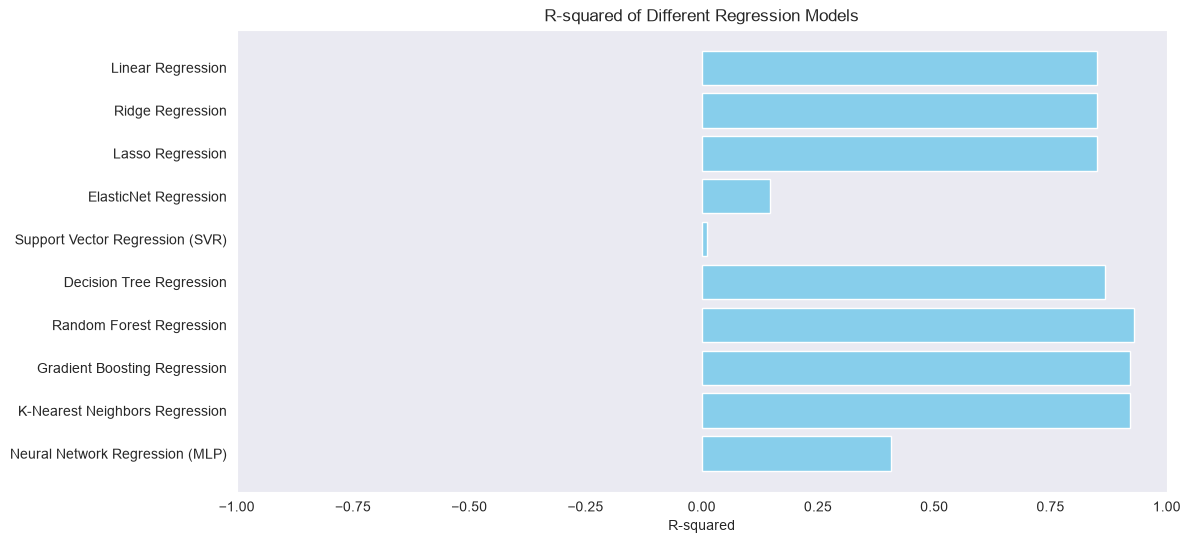

In [30]:

#Define Models and Perform Training and Evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'ElasticNet Regression': ElasticNet(alpha=1.0, l1_ratio=0.5),
    'Support Vector Regression (SVR)': SVR(kernel='rbf'),
    'Decision Tree Regression': DecisionTreeRegressor(),
    'Random Forest Regression': RandomForestRegressor(n_estimators=100),
    'Gradient Boosting Regression': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1),
    'K-Nearest Neighbors Regression': KNeighborsRegressor(n_neighbors=5),
    'Neural Network Regression (MLP)': MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam')
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    # Train the model
    model.fit(X_train, Y_train)

    # Predict on test set
    Y_pred = model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    # Store results
    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    # Print results
    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame for visualization
results_df = pd.DataFrame(results)
print(results_df)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()


In [31]:
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 60476034.55442447
Loaded Random Forest Regression - R-squared: 0.9299919950370628
